# What is the per-garden GWAS trait measuring, and should it just be ecotype frequency?

The per-garden GWAS (`r3_persite_gwas/`) runs **one LMM per garden** on a per-founder trait
`s`, the *selection coefficient* built by `build_selection_trait.py`. This notebook asks three
things about that trait, in order:

1. **What is it, mechanically?** — unroll the formula and see which quantities it is made of.
2. **Does it track actual ecotype frequency?** — the thing we can observe directly.
3. **Do the per-site vectors make sense?** — does a trait built this way recover something we
   independently believe about these ecotypes?

and then: **would plain ecotype frequency be a simpler trait that loses nothing?**

## The one fact that simplifies the whole question

`gemma_persite_gwas.py:74` rank-inverse-normalizes the trait **within each site** before GEMMA
sees it:

```python
P = norm.ppf((rankdata(Smat[si]) - 0.5) / N)
```

So **any monotone transform of a trait gives a byte-identical GWAS.** `freq_last`,
`log(freq_last)` and `logit(freq_last)` are the *same trait*. The only choices that actually
change a result are choices that change the founder *ranking* within a site — which, here,
means one thing: whether the trait is a **level** (where a founder ended up) or a **change**
(how far it moved from where it started).


## Setup

In [1]:

import os
import numpy as np, pandas as pd
import matplotlib as mpl, matplotlib.pyplot as plt
from scipy import stats

mpl.rcParams.update({"figure.dpi": 120, "savefig.dpi": 150, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
ROOT = "/global/scratch/projects/fc_moilab/tbellg/kmate"
R    = f"{ROOT}/analysis/grenenet_selection/r3_persite_gwas/results"
PLOT = f"{R}/varexp/plots"
os.makedirs(PLOT, exist_ok=True)

d = np.load(f"{R}/varexp/selection_s_matrix.npz", allow_pickle=True)
S, p0, FL     = d["S"], d["p0"], d["freq_last"]
bio1, sites   = d["bio1"], d["sites"]
founders      = d["founders"].astype(str)
nS, nF        = S.shape

ECO = ("/global/scratch/users/tbellg/gea_grene-net/key_files/"
       "1001g_regmap_grenet_ecotype_info_corrected_bioclim_2024May16.csv")
e   = pd.read_csv(ECO)
idc = [c for c in e.columns if "ecotype" in c.lower() or c.lower() == "id"][0]
e[idc] = e[idc].astype(str)
em   = e.drop_duplicates(idc).set_index(idc)
home = np.array([float(em.loc[f, "bio1"]) if f in em.index else np.nan for f in founders])

order = np.argsort(bio1)                      # cold -> warm, used everywhere
cmap  = plt.get_cmap("coolwarm")
cnorm = plt.Normalize(bio1.min(), bio1.max())
scol  = [cmap(cnorm(b)) for b in bio1]

print(f"{nS} gardens x {nF} founders | bio1 {bio1.min():.1f}..{bio1.max():.1f} C")
print(f"home climate matched for {np.isfinite(home).sum()}/{nF} founders")
print(f"S: min {S.min():.2f} median {np.median(S):.2f} max {S.max():.2f}")


30 gardens x 231 founders | bio1 6.0..21.6 C
home climate matched for 231/231 founders
S: min -3.85 median -0.76 max 1.54


## 1. What the trait is, unrolled

`build_selection_trait.py` fits, per garden and per plot, an OLS slope of `logit(h)` on
generation, with **generation 0 pinned to the seed-mix `p0`**, then averages over plots:

$$s_{f,\text{site}} \;=\; \frac{\sum_t (t-\bar t)\,\mathrm{logit}(h_{f,t})}{\sum_t (t-\bar t)^2}$$

With the usual four timepoints $t=[0,1,2,3]$ this is a **fixed weighted sum**, and it is worth
seeing the weights written out, because one of them is not like the others.


In [2]:

t  = np.array([0., 1., 2., 3.])
tc = t - t.mean()
w  = tc / (tc @ tc)
print("s = " + "  ".join(f"{wi:+.2f}*logit(h_gen{int(ti)})" for wi, ti in zip(w, t)))
print()
print("  gen0 carries the single largest-magnitude weight (-0.30), and gen0 is NOT a")
print("  per-garden measurement -- it is the shared seed-mix p0, IDENTICAL in all 30 gardens.")
print()

def logit(p, eps=1e-4):
    p = np.clip(p, eps, 1 - eps)
    return np.log(p / (1 - p))

shared = w[0] * logit(p0)                       # the part of s common to every garden
r2 = np.array([stats.pearsonr(S[j], shared).statistic ** 2 for j in range(nS)])
print(f"variance of the shared p0 term       : {shared.var():.4f}")
print(f"mean per-garden variance of s        : {S.var(axis=1).mean():.4f}")
print(f"R^2 (shared p0 term alone vs s)      : mean {r2.mean():.3f}  range [{r2.min():.3f}, {r2.max():.3f}]")
print()
print("So the shared anchor is REAL but SMALL -- it accounts for ~7% of the trait, not most of it.")


s = -0.30*logit(h_gen0)  -0.10*logit(h_gen1)  +0.10*logit(h_gen2)  +0.30*logit(h_gen3)

  gen0 carries the single largest-magnitude weight (-0.30), and gen0 is NOT a
  per-garden measurement -- it is the shared seed-mix p0, IDENTICAL in all 30 gardens.

variance of the shared p0 term       : 0.0235
mean per-garden variance of s        : 0.2521
R^2 (shared p0 term alone vs s)      : mean 0.067  range [0.007, 0.214]

So the shared anchor is REAL but SMALL -- it accounts for ~7% of the trait, not most of it.


**Reading.** The trait is a change measure anchored on a quantity every garden shares. That
shared anchor mechanically induces *some* correlation between gardens and *some* dependence on
founding frequency, but at ~7% of trait variance it is **not** the main story. Worth knowing,
not worth alarm.


## 2. The trait vectors, garden by garden

One panel per garden, ordered cold → warm. Each shows the distribution of `s` across the 231
founders, with the garden's own median marked.


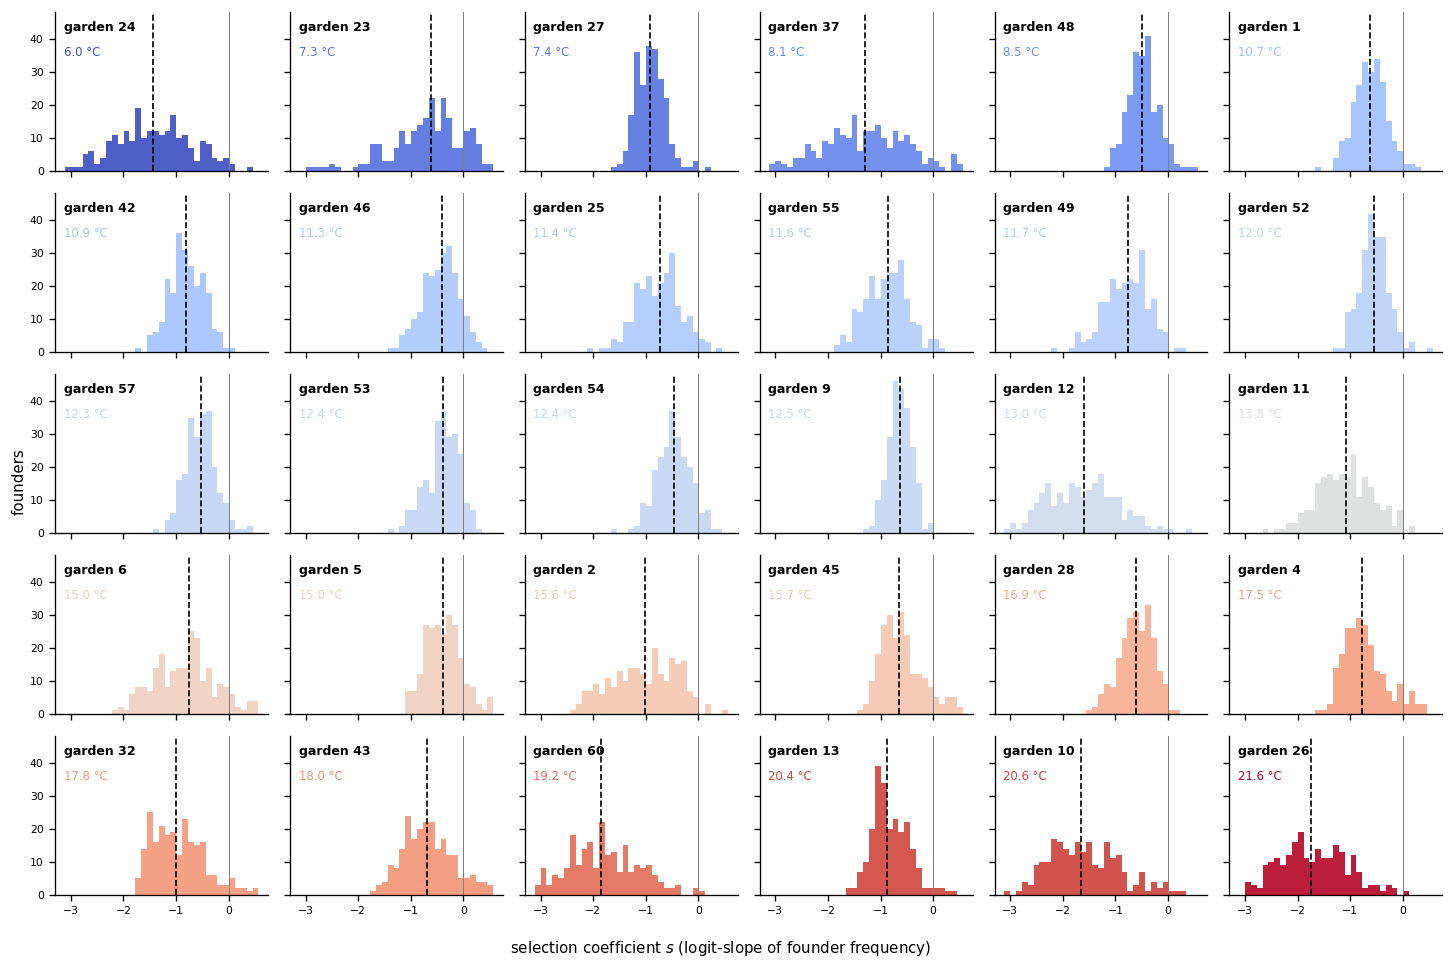

per-garden summary (cold -> warm):
 garden  bio1  median_s  sd_s  frac_declining
     24   6.0    -1.434 0.772           0.978
     23   7.3    -0.614 0.728           0.827
     27   7.4    -0.918 0.273           0.996
     37   8.1    -1.297 0.833           0.948
     48   8.5    -0.489 0.293           0.935
      1  10.7    -0.630 0.316           0.974
     42  10.9    -0.816 0.318           0.996
     46  11.3    -0.415 0.338           0.905
     25  11.4    -0.726 0.417           0.961
     55  11.6    -0.864 0.402           0.978
     49  11.7    -0.765 0.419           0.991
     52  12.0    -0.556 0.292           0.970
     57  12.3    -0.524 0.288           0.965
     53  12.4    -0.385 0.316           0.913
     54  12.4    -0.460 0.359           0.918
      9  12.5    -0.631 0.218           1.000
     12  13.0    -1.591 0.682           0.991
     11  13.8    -1.089 0.524           0.987
      6  15.0    -0.761 0.618           0.900
      5  15.0    -0.388 0.341           0.883

In [3]:

ncol = 6; nrow = int(np.ceil(nS / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(2.05 * ncol, 1.62 * nrow),
                         sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()
lo, hi = np.percentile(S, [0.5, 99.5])
for k, j in enumerate(order):
    ax = axes[k]
    ax.hist(S[j], bins=np.linspace(lo, hi, 34), color=scol[j], edgecolor="none", alpha=.9)
    ax.axvline(np.median(S[j]), color="k", lw=1, ls="--")
    ax.axvline(0, color="grey", lw=.6)
    ax.annotate(f"garden {sites[j]}", (.04, .88), xycoords="axes fraction",
                fontsize=7.5, fontweight="bold")
    ax.annotate(f"{bio1[j]:.1f} °C", (.04, .72), xycoords="axes fraction",
                fontsize=7, color=cmap(cnorm(bio1[j])))
    ax.tick_params(labelsize=6.5)
for ax in axes[nS:]:
    ax.axis("off")
fig.supxlabel("selection coefficient $s$ (logit-slope of founder frequency)", fontsize=9)
fig.supylabel("founders", fontsize=9)
fig.tight_layout()
fig.savefig(f"{PLOT}/trait_s_by_garden.png", bbox_inches="tight")
plt.show()

print("per-garden summary (cold -> warm):")
tb = pd.DataFrame({"garden": sites[order], "bio1": bio1[order].round(1),
                   "median_s": np.median(S, axis=1)[order].round(3),
                   "sd_s": S.std(axis=1)[order].round(3),
                   "frac_declining": (S < 0).mean(axis=1)[order].round(3)})
print(tb.to_string(index=False))


**Reading.** Every garden has a *negative* median `s` — most founders decline. That is not a
bug and not selection acting against most ecotypes: `h` is compositional (it sums to 1 across
231 founders), so if a handful of winners take a large share, the majority must fall. The
spread, not the location, is the informative part, and rank-normalization discards the location
anyway.


## 3. Does `s` track actual ecotype frequency?

This is the question that motivated the notebook. `freq_last` is the directly observed thing —
each founder's mixture frequency in the **final sampled generation** at that garden. If `s` and
`freq_last` rank founders the same way, the selection-coefficient machinery is not buying much.


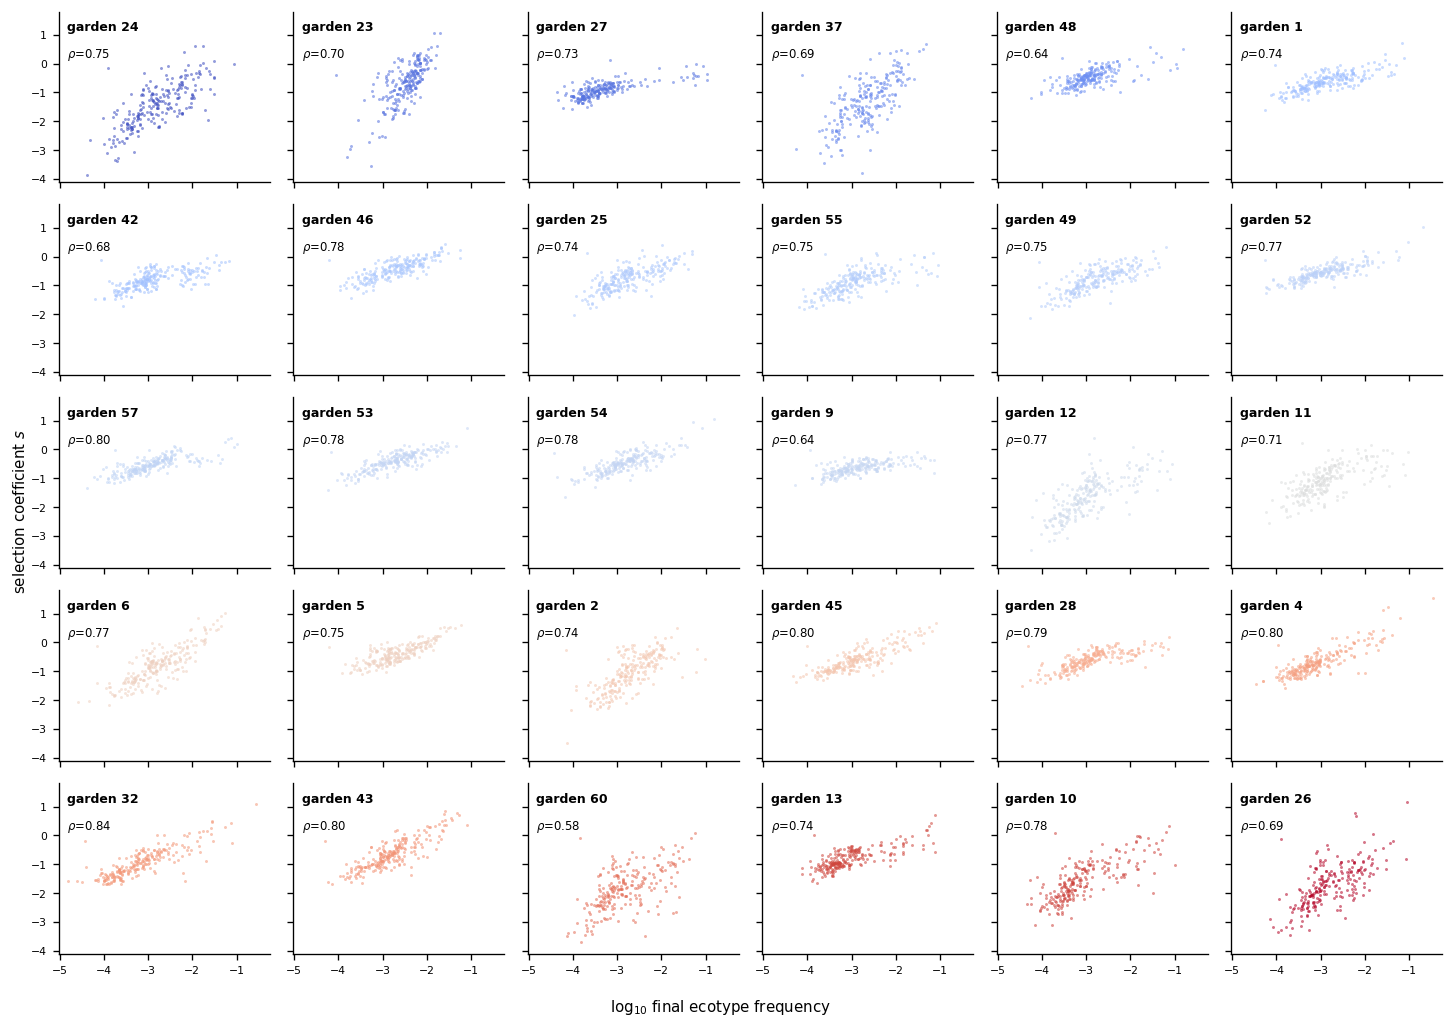

spearman(s, freq_last) across gardens: mean +0.743  range [+0.579, +0.836]
spearman(s, log freq_last   ) mean +0.743
spearman(s, freq_last - p0  ) mean +0.717
spearman(s, freq_last / p0  ) mean +0.866


In [4]:

fig, axes = plt.subplots(nrow, ncol, figsize=(2.05 * ncol, 1.72 * nrow), sharex=True, sharey=True)
axes = np.atleast_1d(axes).ravel()
rho = np.array([stats.spearmanr(S[j], FL[j]).statistic for j in range(nS)])
for k, j in enumerate(order):
    ax = axes[k]
    ax.scatter(np.log10(FL[j]), S[j], s=3.2, color=scol[j], alpha=.55, lw=0)
    ax.annotate(f"garden {sites[j]}", (.04, .89), xycoords="axes fraction",
                fontsize=7.5, fontweight="bold")
    ax.annotate(r"$\rho$=" + f"{rho[j]:.2f}", (.04, .73), xycoords="axes fraction", fontsize=7)
    ax.tick_params(labelsize=6.5)
for ax in axes[nS:]:
    ax.axis("off")
fig.supxlabel("log$_{10}$ final ecotype frequency", fontsize=9)
fig.supylabel("selection coefficient $s$", fontsize=9)
fig.tight_layout()
fig.savefig(f"{PLOT}/trait_s_vs_freq_last.png", bbox_inches="tight")
plt.show()

print(f"spearman(s, freq_last) across gardens: mean {rho.mean():+.3f}  "
      f"range [{rho.min():+.3f}, {rho.max():+.3f}]")
for nm, alt in [("log freq_last", np.log(FL)), ("freq_last - p0", FL - p0),
                ("freq_last / p0", FL / p0)]:
    rr = np.mean([stats.spearmanr(S[j], alt[j]).statistic for j in range(nS)])
    print(f"spearman(s, {nm:16s}) mean {rr:+.3f}")


**Reading.** `s` and final ecotype frequency agree strongly — mean Spearman **+0.74**, never
below +0.58 in any garden. The selection coefficient is, to a large extent, a re-expression of
*which ecotypes ended up common*. It is not measuring something orthogonal to frequency.

That said +0.74 is not +1.0, so the two are not interchangeable. The gap is the part of `s`
that references where a founder *started*.


## 4. Would plain ecotype frequency be simpler? — the candidate traits

Given the rank-normalization, there are only a few genuinely distinct choices:

| trait | what it asks | kind |
|---|---|---|
| `s` (current) | how fast did this founder's frequency climb? | change |
| `freq_last` | where did this founder end up? | **level** |
| `freq_last / p0` | how far did it move from where it started? | change |
| `s − founder mean` | where does it do better *than its own average*? | pure G×E |

Compared on the three properties that matter for a per-garden GWAS.


In [5]:

def rankz(M):
    return np.vstack([stats.zscore(stats.rankdata(r)) for r in M])

traits = {"s (current)": S, "freq_last (level)": FL,
          "freq_last/p0 (fold-change)": FL / p0, "s - founder mean (pure GxE)": S - S.mean(0)}

print("Are any of these the SAME trait after rank-normalization?")
for a, b, na, nb in [(FL, np.log(FL), "freq_last", "log freq_last"),
                     (FL, np.log(FL) - np.log(p0), "freq_last", "log(freq_last/p0)"),
                     (S, np.log(FL / p0), "s", "log(freq_last/p0)")]:
    rr = np.mean([stats.spearmanr(a[j], b[j]).statistic for j in range(nS)])
    print(f"  spearman({na:10s}, {nb:18s}) = {rr:+.4f}"
          + ("   <- IDENTICAL GWAS" if rr > 0.99999 else ""))

rows = []
for nm, M in traits.items():
    Z  = rankz(M)
    C  = np.corrcoef(Z); iu = np.triu_indices(nS, 1)
    ev = np.clip(np.linalg.eigvalsh(C)[::-1], 0, None)
    rp = np.mean([stats.spearmanr(M[j], p0).statistic for j in range(nS)])
    rows.append(dict(trait=nm, xgarden_r=C[iu].mean(), PC1_frac=ev[0] / ev.sum(), r_with_p0=rp))
T = pd.DataFrame(rows)
print()
print(T.to_string(index=False, float_format=lambda v: f"{v:+.3f}"))


Are any of these the SAME trait after rank-normalization?
  spearman(freq_last , log freq_last     ) = +1.0000   <- IDENTICAL GWAS
  spearman(freq_last , log(freq_last/p0) ) = +0.9051
  spearman(s         , log(freq_last/p0) ) = +0.8656

                      trait  xgarden_r  PC1_frac  r_with_p0
                s (current)     +0.443    +0.479     -0.192
          freq_last (level)     +0.295    +0.332     +0.243
 freq_last/p0 (fold-change)     +0.251    +0.293     -0.125
s - founder mean (pure GxE)     -0.005    +0.316     +0.033


**Reading.**

- `freq_last` and `log(freq_last)` are **the same trait** — as promised, the transform is free.
- **`freq_last` carries much less shared structure than `s`**: mean cross-garden correlation
  drops 0.44 → 0.30, and the dominant shared axis 48% → 33%. That shared axis is exactly what
  made a marker look "significant in 13 of 30 gardens" — gardens that agree by construction are
  not independent replicates.
- The cost: `freq_last` is a *level*, so it correlates **positively** with founding frequency
  (+0.24) — a founder that started common tends to end common. `s` has the opposite sign
  (−0.19). Neither is zero; they are confounded in opposite directions.


## 5. Do the vectors make sense? — the local-adaptation test

The strongest available check does not involve any marker. If these per-garden vectors capture
real ecotype dynamics, they should recover **local adaptation**: an ecotype from a warm home
should do relatively better as the garden gets warmer.

For each founder take $\gamma_f$ = the slope of its trait across gardens on garden temperature,
then correlate $\gamma_f$ with that founder's **home** `bio1` (1001g provenance). Nothing in the
trait's construction knows about provenance, so a positive correlation is a genuine external
check.


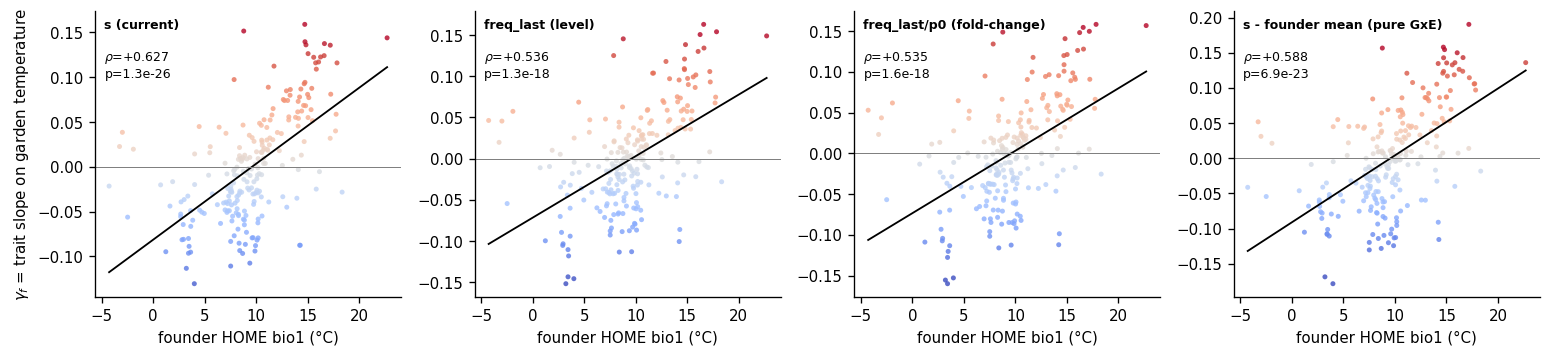

Warm-origin founders doing better in warm gardens => positive rho:
  s (current)                    rho=+0.627  p=1.34e-26
  freq_last (level)              rho=+0.536  p=1.29e-18
  freq_last/p0 (fold-change)     rho=+0.535  p=1.61e-18
  s - founder mean (pure GxE)    rho=+0.588  p=6.86e-23


In [6]:

bc = bio1 - bio1.mean()
gam = {nm: (bc[:, None] * rankz(M)).sum(0) / (bc @ bc) for nm, M in traits.items()}
ok  = np.isfinite(home)

fig, axes = plt.subplots(1, 4, figsize=(13.0, 3.05), sharey=False)
for ax, (nm, g) in zip(axes, gam.items()):
    r = stats.spearmanr(g[ok], home[ok])
    lim = np.abs(np.percentile(g[ok], [1, 99])).max()
    ax.scatter(home[ok], g[ok], s=9, c=g[ok], cmap="coolwarm",
               vmin=-lim, vmax=lim, lw=0, alpha=.8)
    b, a = np.polyfit(home[ok], g[ok], 1)
    xs = np.linspace(home[ok].min(), home[ok].max(), 20)
    ax.plot(xs, a + b * xs, color="k", lw=1.1)
    ax.axhline(0, color="grey", lw=.6)
    ax.annotate(nm, (.03, .94), xycoords="axes fraction", fontsize=7.5, fontweight="bold")
    ax.annotate(r"$\rho$=" + f"{r.statistic:+.3f}\np={r.pvalue:.1e}", (.03, .77),
                xycoords="axes fraction", fontsize=7.5)
    ax.set_xlabel("founder HOME bio1 (°C)")
axes[0].set_ylabel(r"$\gamma_f$ = trait slope on garden temperature")
fig.tight_layout()
fig.savefig(f"{PLOT}/trait_local_adaptation.png", bbox_inches="tight")
plt.show()

print("Warm-origin founders doing better in warm gardens => positive rho:")
for nm, g in gam.items():
    r = stats.spearmanr(g[ok], home[ok])
    print(f"  {nm:30s} rho={r.statistic:+.3f}  p={r.pvalue:.2e}")


**Reading — the trait makes sense.** Every version recovers local adaptation at
$\rho \approx +0.54$ to $+0.63$, $p \sim 10^{-18}$ to $10^{-26}$. Ecotypes from warm homes gain
as gardens warm; ecotypes from cold homes lose. Nothing in `build_selection_trait.py` has access
to provenance, so this is a real external validation of the per-garden vectors.

**And the current trait wins this test.** `s` scores highest (+0.63) — above `freq_last`
(+0.54). Referencing the founding frequency *does* buy something: it removes part of the
"started common, ended common" inertia that dilutes the level-based trait.


## 6. Where the two traits disagree

Cross-garden correlation structure, side by side. This is the property that decides whether
"significant in *k* gardens" means anything.


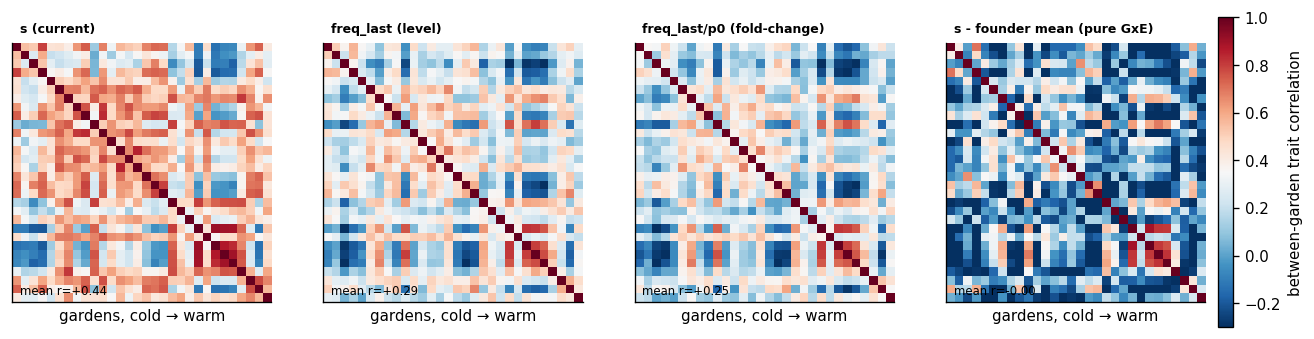

effective number of INDEPENDENT gardens (Li & Ji, of 30):
  s (current)                     12.0
  freq_last (level)               16.0
  freq_last/p0 (fold-change)      17.0
  s - founder mean (pure GxE)     17.0


In [7]:

fig, axes = plt.subplots(1, 4, figsize=(13.2, 3.35))
for ax, (nm, M) in zip(axes, traits.items()):
    C = np.corrcoef(rankz(M))[np.ix_(order, order)]
    im = ax.imshow(C, vmin=-.3, vmax=1, cmap="RdBu_r")
    iu = np.triu_indices(nS, 1)
    ax.annotate(nm, (.03, 1.04), xycoords="axes fraction", fontsize=7.5, fontweight="bold")
    ax.annotate(f"mean r={np.corrcoef(rankz(M))[iu].mean():+.2f}", (.03, .03),
                xycoords="axes fraction", fontsize=7, color="k")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel("gardens, cold → warm")
fig.colorbar(im, ax=axes, fraction=.018, pad=.01, label="between-garden trait correlation")
fig.savefig(f"{PLOT}/trait_xgarden_corr.png", bbox_inches="tight")
plt.show()

nz = {nm: np.linalg.eigvalsh(np.corrcoef(rankz(M)))[::-1] for nm, M in traits.items()}
print("effective number of INDEPENDENT gardens (Li & Ji, of 30):")
for nm, ev in nz.items():
    ev = np.clip(ev, 0, None)
    meff = sum((x >= 1) + (x - np.floor(x)) for x in ev)
    print(f"  {nm:30s} {meff:5.1f}")


**Reading.** The current trait leaves ~13 effective independent gardens out of 30; the
frequency-level trait leaves more. Whichever trait is used, **30 gardens are not 30 independent
tests**, and any "significant in *k* gardens" count has to be read against the effective number,
not the nominal one.


## Summary

**What the trait is.** A fixed weighted sum of `logit(h)` over four timepoints,
`-0.30, -0.10, +0.10, +0.30`. The heaviest weight sits on generation 0, which is the *shared*
seed-mix `p0`, not a per-garden measurement — but that shared anchor is only ~7% of trait
variance, so it is a footnote, not the main driver.

**Does it track ecotype frequency?** Yes, strongly: mean Spearman **+0.74** with final ecotype
frequency, never below +0.58 in any garden. `s` is largely a re-expression of which ecotypes
ended up common.

**Do the vectors make sense?** Yes, and this is the clearest result here. All trait versions
recover **local adaptation** from provenance data they never saw — warm-origin ecotypes gain as
gardens warm, $\rho = +0.54 \ldots +0.63$, $p$ down to $10^{-26}$.

**Should we just use ecotype frequency?** It is a real option and it is genuinely simpler, but
it is a **trade, not a free win**:

| | `s` (current) | `freq_last` |
|---|---|---|
| recovers local adaptation | **+0.63** | +0.54 |
| shared cross-garden axis | 48% (worse) | **33%** |
| confounded with founding frequency | −0.19 | +0.24 |
| interpretation | rate of change | where it ended up |

`freq_last` buys **less inter-garden redundancy**; `s` buys **a cleaner local-adaptation
signal**. Because the pipeline rank-normalizes per site, switching between `freq_last`,
`log(freq_last)` and `logit(freq_last)` is a no-op — only the level-vs-change decision matters.

**What this does not settle.** Nothing here re-runs GEMMA, so it does not say which trait gives
better *markers* — only which has better properties. Both traits leave real confounding with
founding frequency, in opposite directions, and `p0` is not in the GEMMA model either way.
